# Evaluación temporal y diagnósticos de los modelos

Los artefactos completos permiten verificar las métricas, reconstruir errores de las 24 horas y examinar variación temporal, segmentos y residuos. Se utilizan exclusivamente predicciones e historiales ya guardados en la ejecución v2. El análisis secundario temporal está registrado antes de cargar esas predicciones; no constituye un diseño confirmatorio anterior al entrenamiento.

In [1]:
from pathlib import Path
import json,itertools
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
SHA='02ff447d94fa78e1cde323fa2382da5bce24fb6e'
SNAP=ROOT/'results/repositorio'/SHA; R=SNAP/'results/base_v2'
OUT=ROOT/'results/jbook/modelos';OUT.mkdir(parents=True,exist_ok=True)
plan=json.loads((OUT/'plan_analisis_temporal.json').read_text(encoding='utf-8'))
env=json.loads((R/'entorno_final.json').read_text(encoding='utf-8'))
escala=float(env['escala_mase'])
runs=pd.read_csv(R/'final_runs.csv')
modelos=['mlp','arx_lineal','lstm','cnn1d']; neuronales=['mlp','lstm','cnn1d']
etiquetas={'mlp':'MLP','arx_lineal':'ARX','lstm':'LSTM','cnn1d':'CNN1D'}
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
importacion=json.loads((SNAP/'IMPORTACION.json').read_text(encoding='utf-8'))
huellas={f['archivo']:f for f in importacion['archivos']}
indice=pd.read_csv(R/'indice_artefactos.csv')
for fila in indice.itertuples():
    info=huellas['results/base_v2/'+fila.archivo]
    assert info['sha256']==fila.sha256 and info['bytes']==fila.bytes
identidades=[]
for p in sorted((R/'ajustes/final').glob('*/identidad.json')):
    ident=json.loads(p.read_text(encoding='utf-8'))
    identidades.append({**ident,'carpeta':p.parent})
ident=pd.DataFrame(identidades)
assert len(ident)==780 and not ident.duplicated(['modelo','semilla']).any()
pred={}; carpetas={}; semillas=np.arange(1000,1195); y=None; origen=None
for nombre in modelos:
    d=ident.loc[ident.modelo==nombre].sort_values('semilla')
    assert np.array_equal(d.semilla.to_numpy(),semillas)
    pila=[]
    for fila in d.itertuples():
        with np.load(fila.carpeta/'predicciones.npz',allow_pickle=False) as z:
            if y is None:y=z['y'].copy();origen=z['origen'].copy()
            assert np.array_equal(z['y'],y) and np.array_equal(z['origen'],origen)
            assert z['yhat'].shape==y.shape and np.isfinite(z['yhat']).all()
            pila.append(z['yhat'].copy())
        carpetas[(nombre,fila.semilla)]=fila.carpeta
    pred[nombre]=np.stack(pila)
fechas=pd.to_datetime(origen,unit='ns',utc=True).tz_convert('America/Bogota')
assert fechas.is_unique and fechas.is_monotonic_increasing
esperadas=pd.date_range('2022-01-01','2025-12-31',freq='D',tz='America/Bogota')
assert len(fechas)==len(esperadas) and (fechas==esperadas).all() and y.shape==(1461,24)
metricas=[]; loss_h={}; loss_d={}; resid={}
var_y=float(np.var(y))
for nombre in modelos:
    error=pred[nombre]-y[None,:,:]
    absoluto=np.abs(error); mse=np.mean(error**2,axis=(1,2))
    rmse=np.sqrt(mse); mae=absoluto.mean(axis=(1,2))
    esperado=runs.loc[runs.modelo==nombre].sort_values('semilla')
    assert np.allclose(mae,esperado.MAE,rtol=1e-10)
    assert np.allclose(rmse,esperado.RMSE,rtol=1e-10)
    assert np.allclose(mae/escala,esperado.MASE,rtol=1e-10)
    for h in [1,12,24]:
        assert np.allclose(absoluto[:,:,h-1].mean(axis=1)/escala,esperado[f'MASE_h{h}'],rtol=1e-10)
    loss_h[nombre]=absoluto.mean(axis=0)/escala
    loss_d[nombre]=loss_h[nombre].mean(axis=1)
    resid[nombre]=error[0].mean(axis=1)
    for i,s in enumerate(semillas):
        metricas.append({'modelo':nombre,'semilla':int(s),'MAE':float(mae[i]),
            'RMSE':float(rmse[i]),'MASE':float(mae[i]/escala),
            'R2':float(1-mse[i]/var_y),'sesgo_kWh':float(error[i].mean())})
metricas=pd.DataFrame(metricas)
metricas.to_csv(OUT/'metricas_desde_predicciones.csv',index=False)
n_dias=len(fechas);n_artefactos=len(indice);n_pred=len(ident)

with np.load(OUT/'referencias_desde_observaciones.npz',allow_pickle=False) as z:
    assert np.array_equal(z['y'],y) and np.array_equal(z['origen'],origen)
    refs=['ingenuo_24h','ingenuo_168h','persistencia']
    for nombre in refs:loss_h[nombre]=np.abs(z[nombre]-y)/escala;loss_d[nombre]=loss_h[nombre].mean(axis=1)
etiquetas.update({'ingenuo_24h':'Ingenuo diario','ingenuo_168h':'Ingenuo semanal','persistencia':'Persistencia'})


Se verifican 9,840 artefactos indexados y 780 archivos finales de predicciones, con 1461 orígenes comunes y 24 horas por día. Las métricas reconstruidas coinciden con las publicadas; no hay días ausentes ni orígenes duplicados en la prueba. El orden de semillas y las etiquetas son idénticos entre familias.

## Métricas complementarias y errores por horizonte

R² se calcula sobre todos los intervalos horarios mediante 1 − SSE/SST, con la misma varianza objetivo para cada semilla. El sesgo conserva signo: positivo indica sobreestimación. La tabla complementa MAE, RMSE y MASE del benchmark, sin sustituir la métrica primaria.

,R2_media,R2_DE,IC95_inf,IC95_sup,Sesgo_medio_kWh
Modelo,,,,,
ARX,0.9565,0.0048,0.9558,0.9572,4586.6804
CNN1D,0.7660,0.0119,0.7643,0.7676,-17154.7486
LSTM,0.8187,0.0831,0.8070,0.8305,-20097.1056
MLP,0.9714,0.0027,0.9710,0.9718,17037.1894


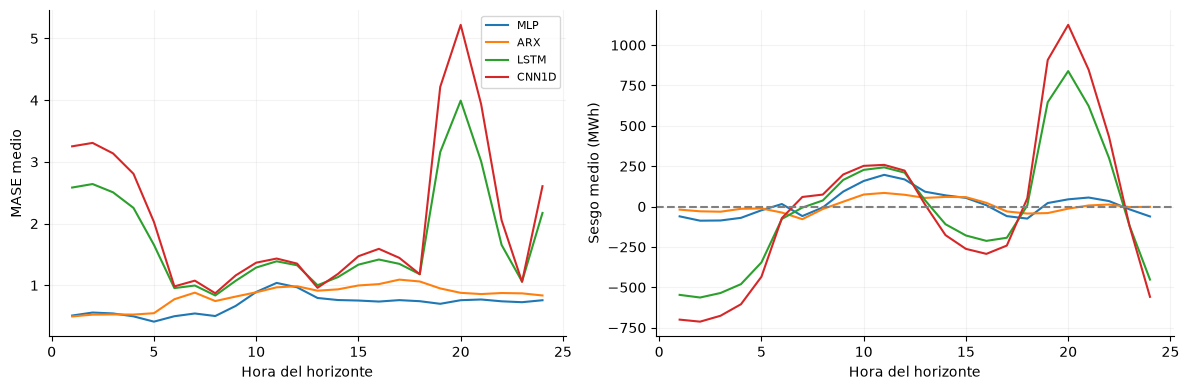

In [2]:
complementarias=[]
for nombre,d in metricas.groupby('modelo'):
    n=len(d);m=d.R2.mean();sd=d.R2.std(ddof=1);h=stats.t.ppf(.975,n-1)*sd/np.sqrt(n)
    complementarias.append({'Modelo':etiquetas[nombre],'R2_media':m,'R2_DE':sd,'IC95_inf':m-h,'IC95_sup':m+h,
        'Sesgo_medio_kWh':d.sesgo_kWh.mean()})
display(pd.DataFrame(complementarias).set_index('Modelo').round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
filas_h=[]
for nombre in modelos:
    axes[0].plot(np.arange(1,25),loss_h[nombre].mean(axis=0),label=etiquetas[nombre])
    sesgo=(pred[nombre]-y[None,:,:]).mean(axis=(0,1))
    axes[1].plot(np.arange(1,25),sesgo/1000,label=etiquetas[nombre])
    for h in range(24):
        filas_h.append({'modelo':nombre,'horizonte':h+1,'MASE':float(loss_h[nombre][:,h].mean()),
                        'sesgo_kWh':float(sesgo[h])})
axes[0].set(xlabel='Hora del horizonte',ylabel='MASE medio');axes[0].legend(fontsize=8)
axes[1].axhline(0,color='grey',ls='--');axes[1].set(xlabel='Hora del horizonte',ylabel='Sesgo medio (MWh)')
fig.tight_layout();display(fig);plt.close(fig)
pd.DataFrame(filas_h).to_csv(OUT/'errores_24_horizontes.csv',index=False)
pico_mlp=int(np.argmax(loss_h['mlp'].mean(axis=0))+1)


El mayor MASE horario de MLP aparece en h = 11. La curva completa distingue errores de forma del perfil que tres puntos aislados no muestran. El sesgo firmado identifica horas con sobreestimación o subestimación persistente, mientras MASE cuantifica magnitud sin cancelación de signos.

## Curvas de aprendizaje completas

Se muestra la semilla 1000, fijada antes de revisar curvas, para cada familia. Las funciones de pérdida difieren entre arquitecturas; su magnitud se interpreta dentro de cada panel. Las curvas completas de todas las ejecuciones quedan conservadas en la instantánea.

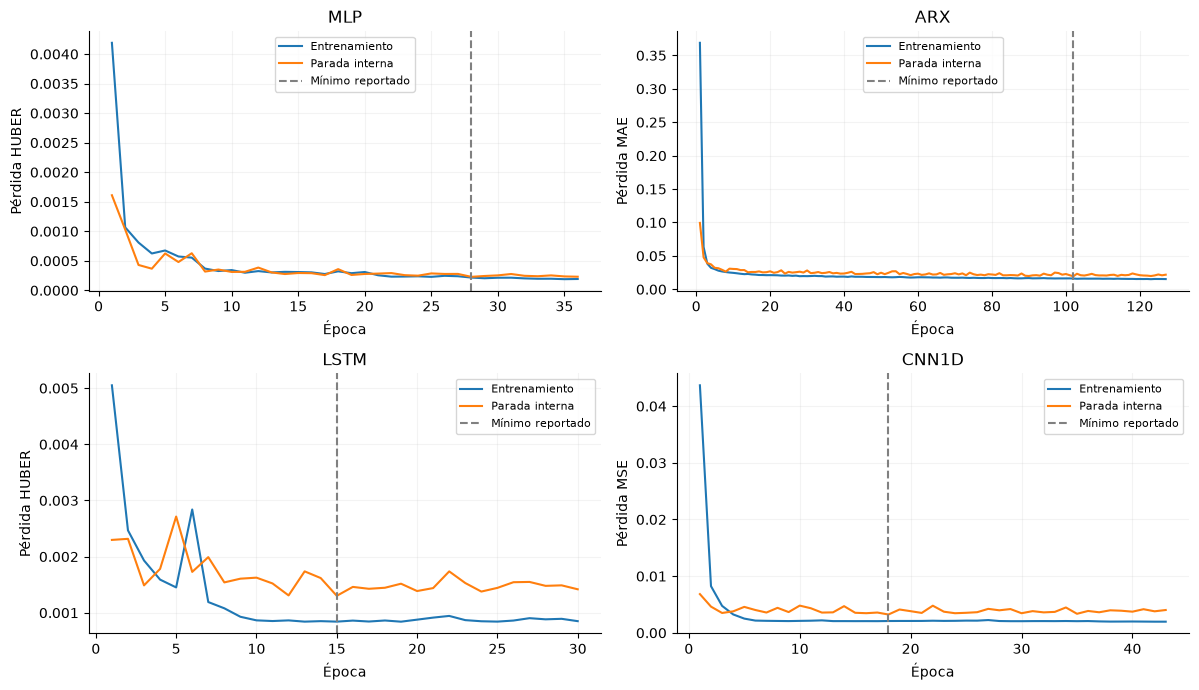

In [3]:
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,nombre in zip(axes.ravel(),modelos):
    hist=pd.DataFrame(json.loads((carpetas[(nombre,1000)]/'historia.json').read_text(encoding='utf-8')))
    fila=runs.loc[(runs.modelo==nombre)&(runs.semilla==1000)].iloc[0]
    ax.plot(hist.epoca,hist.train_loss,label='Entrenamiento')
    ax.plot(hist.epoca,hist.val_loss,label='Parada interna')
    ax.axvline(fila.mejor_epoca,color='grey',ls='--',label='Mínimo reportado')
    ax.set(title=etiquetas[nombre],xlabel='Época',ylabel='Pérdida '+json.loads(fila.params)['perdida'].upper())
    ax.legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)


En la semilla 1000, MLP presenta curvas de ajuste y parada interna próximas tras el descenso inicial. LSTM y CNN1D mantienen una separación mayor dentro de sus respectivas funciones de pérdida, compatible con una generalización interna más limitada. La línea vertical indica el mínimo reportado; la distribución de épocas de las 195 ejecuciones complementa este ejemplo.

## Predicción frente a demanda observada

La ventana del 1 al 7 de julio de 2023 se fijó antes de revisar las trayectorias. Se muestran la demanda observada, la media de predicciones y el rango p10–p90 entre inicializaciones. Esa banda representa dispersión algorítmica; no es un intervalo predictivo calibrado.

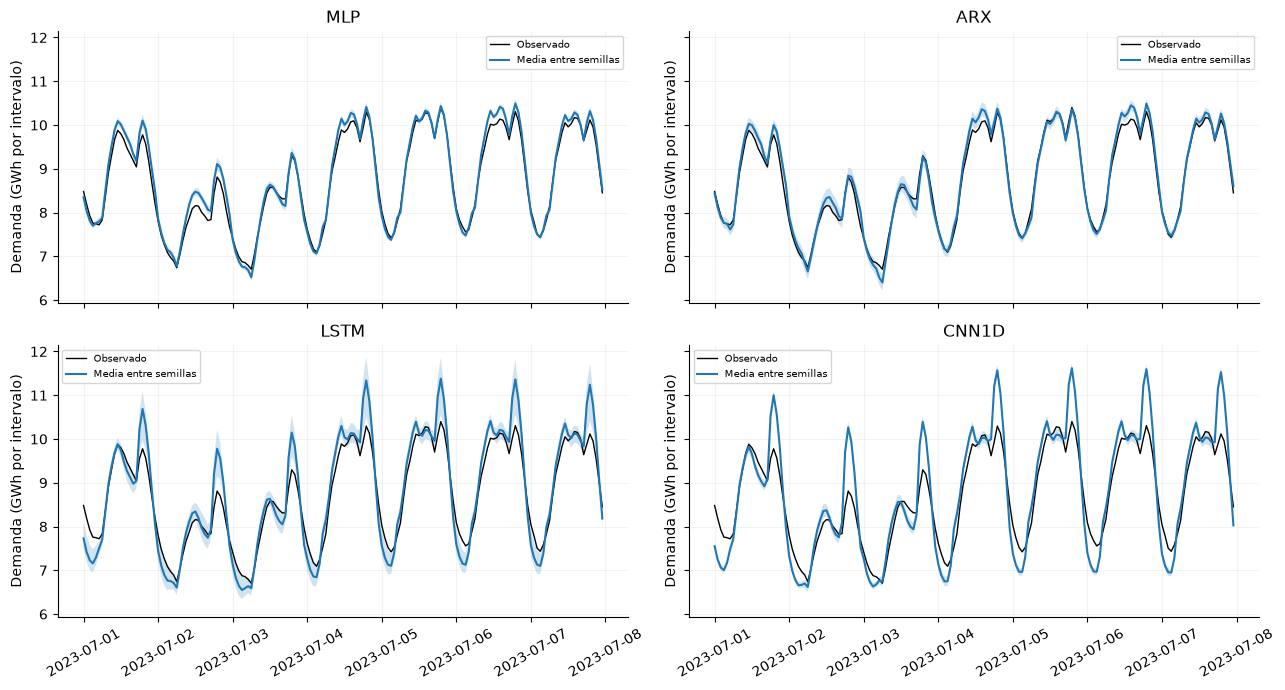

In [4]:
sel=(fechas>=pd.Timestamp('2023-07-01',tz='America/Bogota'))&(fechas<pd.Timestamp('2023-07-08',tz='America/Bogota'))
tiempos=pd.DatetimeIndex([f+pd.Timedelta(hours=h) for f in fechas[sel] for h in range(24)])
fig,axes=plt.subplots(2,2,figsize=(13,7),sharex=True,sharey=True)
for ax,nombre in zip(axes.ravel(),modelos):
    p=pred[nombre][:,sel,:].reshape(len(semillas),-1)
    ax.plot(tiempos,y[sel].ravel()/1e6,color='black',lw=1,label='Observado')
    ax.plot(tiempos,p.mean(axis=0)/1e6,label='Media entre semillas')
    ax.fill_between(tiempos,np.quantile(p,.1,axis=0)/1e6,np.quantile(p,.9,axis=0)/1e6,alpha=.2)
    ax.set(title=etiquetas[nombre],ylabel='Demanda (GWh por intervalo)')
    ax.tick_params(axis='x',rotation=30);ax.legend(fontsize=7)
fig.tight_layout();display(fig);plt.close(fig)


MLP y ARX siguen mejor el perfil observado en esta semana. LSTM y CNN1D sobreestiman picos concretos y alteran la amplitud diaria, especialmente CNN1D. La variación entre inicializaciones no corrige esas desviaciones sistemáticas; la comparación se complementa con los errores de todo el periodo.

## Incertidumbre temporal y comparación pareada

La pérdida diaria de cada familia es el error absoluto medio sobre las 24 horas y las 195 inicializaciones, dividido por la escala fija de MASE. Promediar pérdidas no equivale a evaluar el error de una predicción ensemble. Se remuestrean bloques circulares de 14 días dentro de cada año, preservando el tamaño de 2022, 2023, 2024 y 2025 y aplicando los mismos índices a todos los métodos.

Los intervalos reflejan variación temporal condicionada a las realizaciones guardadas y a esos años; se reportan separados de los intervalos entre semillas. El contraste bootstrap centra las diferencias bajo igualdad de pérdida media. Las comparaciones neuronales, las de contexto ARX y las de MLP frente a tres ingenuos forman familias separadas de tres hipótesis, con corrección de Holm.

In [5]:
familias={'Neuronales':list(itertools.combinations(neuronales,2)),
          'Contexto ARX':[(n,'arx_lineal') for n in neuronales],
          'Referencias ingenuas':[('mlp',n) for n in refs]}
def pesos_bloques(longitud,B,seed):
    rng=np.random.default_rng(seed);N=len(fechas)
    pesos=np.zeros((B,N),dtype='float64')
    filas=np.arange(B)[:,None]
    for anio in sorted(set(fechas.year)):
        pos=np.flatnonzero(fechas.year==anio);n=len(pos)
        comienzos=rng.integers(0,n,size=(B,int(np.ceil(n/longitud))))
        idx=((comienzos[:,:,None]+np.arange(longitud))%n).reshape(B,-1)[:,:n]
        np.add.at(pesos,(filas,pos[idx]),1/N)
    assert np.allclose(pesos.sum(axis=1),1)
    return pesos

def dm_hln(d,rezagos=14):
    # Los orígenes distan 24 h: cada horizonte horario se evalúa una vez al día.
    # HLN usa h=1 origen no solapado; HAC conserva dependencia entre días.
    d=np.asarray(d,dtype=float);T=len(d);centrado=d-d.mean()
    gamma0=float(centrado@centrado/T)
    lrv=gamma0+2*sum((1-l/(rezagos+1))*float(centrado[l:]@centrado[:-l]/T) for l in range(1,rezagos+1))
    if lrv<=0:raise ValueError('Varianza HAC no positiva')
    h=1;correccion=np.sqrt((T+1-2*h+h*(h-1)/T)/T)
    estadistico=float(d.mean()/np.sqrt(lrv/T)*correccion)
    return estadistico,float(2*stats.t.sf(abs(estadistico),T-1))

B=plan['bootstrap_replicas'];pesos=pesos_bloques(plan['bloque_dias'],B,plan['semilla'])
boot_h={n:pesos@loss_h[n] for n in [*modelos,*refs]}
boot_d={n:boot_h[n].mean(axis=1) for n in [*modelos,*refs]}
temporal=[]
for nombre in modelos:
    ci=np.quantile(boot_d[nombre],[.025,.975])
    temporal.append({'Modelo':etiquetas[nombre],'MASE':float(loss_d[nombre].mean()),
        'IC95_temporal_inf':ci[0],'IC95_temporal_sup':ci[1],
        'IC95_MAE_inf_kWh':ci[0]*escala,'IC95_MAE_sup_kWh':ci[1]*escala})
display(pd.DataFrame(temporal).set_index('Modelo').round(4))
contrastes=[]
for familia,pares in familias.items():
    for a,b in pares:
        d=loss_d[b]-loss_d[a];m=float(d.mean());rep=boot_d[b]-boot_d[a]
        rel=100*(1-boot_d[a]/boot_d[b]);ci=np.quantile(rep,[.025,.975]);ci_rel=np.quantile(rel,[.025,.975])
        p=(1+np.sum(np.abs(rep-m)>=abs(m)))/(B+1)
        dm,dm_p=dm_hln(d,14)
        contrastes.append({'Familia':familia,'A':a,'B':b,'Delta_MASE_B_menos_A':m,
            'IC95_inf':ci[0],'IC95_sup':ci[1],'Reduccion_A_pct':100*(1-loss_d[a].mean()/loss_d[b].mean()),
            'IC95_reduccion_inf':ci_rel[0],'IC95_reduccion_sup':ci_rel[1],
            'Cohen_dz_diario':m/d.std(ddof=1),'Dias_mejor_A_pct':100*np.mean(d>0),
            'p_bootstrap':p,'DM_HLN':dm,'p_DM':dm_p})
contrastes=pd.DataFrame(contrastes)
for fam,idx in contrastes.groupby('Familia').groups.items():
    contrastes.loc[idx,'p_bootstrap_Holm']=multipletests(contrastes.loc[idx,'p_bootstrap'],method='holm')[1]
    contrastes.loc[idx,'p_DM_Holm']=multipletests(contrastes.loc[idx,'p_DM'],method='holm')[1]
display(contrastes[['Familia','A','B','Delta_MASE_B_menos_A','IC95_inf','IC95_sup',
    'Reduccion_A_pct','IC95_reduccion_inf','IC95_reduccion_sup','Cohen_dz_diario',
    'p_bootstrap','p_bootstrap_Holm','p_DM','p_DM_Holm']].style.format(precision=4,formatter={k:(lambda p:'<1e-300' if p==0 else f'{p:.3g}') for k in ['p_bootstrap','p_bootstrap_Holm','p_DM','p_DM_Holm']}))
contrastes.to_csv(OUT/'contrastes_temporales.csv',index=False)
pd.DataFrame(temporal).to_csv(OUT/'intervalos_temporales.csv',index=False)
n_rechazos=int(((contrastes.Familia=='Neuronales')&(contrastes.p_bootstrap_Holm<.05)).sum())
mlp_arx=contrastes.loc[(contrastes.A=='mlp')&(contrastes.B=='arx_lineal')].iloc[0]
del pesos


,MASE,IC95_temporal_inf,IC95_temporal_sup,IC95_MAE_inf_kWh,IC95_MAE_sup_kWh
Modelo,,,,,
MLP,0.6925,0.6715,0.7144,144788.0851,154032.4696
ARX,0.8313,0.8018,0.8630,172878.4517,186079.0264
LSTM,1.7483,1.7258,1.7719,372103.1567,382047.8053
CNN1D,2.0700,2.0461,2.0945,441177.6399,451604.0092


,Familia,A,B,Delta_MASE_B_menos_A,IC95_inf,IC95_sup,Reduccion_A_pct,IC95_reduccion_inf,IC95_reduccion_sup,Cohen_dz_diario,p_bootstrap,p_bootstrap_Holm,p_DM,p_DM_Holm
0,Neuronales,mlp,lstm,1.0558,1.0382,1.0731,60.3907,59.4338,61.3228,4.2148,0.0001,0.0003,<1e-300,<1e-300
1,Neuronales,mlp,cnn1d,1.3776,1.3581,1.3967,66.5479,65.6999,67.3752,4.8330,0.0001,0.0003,<1e-300,<1e-300
2,Neuronales,lstm,cnn1d,0.3218,0.3162,0.3276,15.5447,15.2674,15.8249,3.3465,0.0001,0.0003,<1e-300,<1e-300
3,Contexto ARX,mlp,arx_lineal,0.1388,0.1189,0.1598,16.6968,14.6271,18.7600,0.4493,0.0001,0.0003,3.96e-36,3.96e-36
4,Contexto ARX,lstm,arx_lineal,-0.9170,-0.9386,-0.8943,-110.3123,-116.4584,-104.1530,-2.4575,0.0001,0.0003,<1e-300,<1e-300
5,Contexto ARX,cnn1d,arx_lineal,-1.2388,-1.2625,-1.2143,-149.0220,-156.6453,-141.3232,-3.0648,0.0001,0.0003,<1e-300,<1e-300
6,Referencias ingenuas,mlp,ingenuo_24h,1.3843,1.3469,1.4231,66.6556,65.8250,67.4745,0.8157,0.0001,0.0003,<1e-300,<1e-300
7,Referencias ingenuas,mlp,ingenuo_168h,0.6624,0.5680,0.7610,48.8915,45.1265,52.3402,0.5168,0.0001,0.0003,5.24e-37,5.24e-37
8,Referencias ingenuas,mlp,persistencia,3.5415,3.5083,3.5739,83.6448,83.1410,84.1373,4.5981,0.0001,0.0003,<1e-300,<1e-300


El bootstrap temporal rechaza igualdad en 3 de los tres contrastes neuronales tras Holm. MLP reduce el error frente a ARX un 16.70 %, con IC temporal [14.63; 18.76] %. Los intervalos no convierten esta evaluación retrospectiva en prueba prospectiva; la comparación exige mantener las mismas fechas y realizaciones.

## Diebold–Mariano por horizonte

La diferencia de pérdida absoluta se evalúa para cada una de las 24 horas. Los pronósticos proceden de orígenes diarios no solapados: la corrección HLN usa un paso diario, no 24 días. La varianza HAC Bartlett considera 14 rezagos diarios para recoger dependencia remanente. Las comparaciones por horizonte se corrigen por Holm en tres familias de 72 hipótesis: redes entre sí, redes frente a ARX y MLP frente a ingenuos.

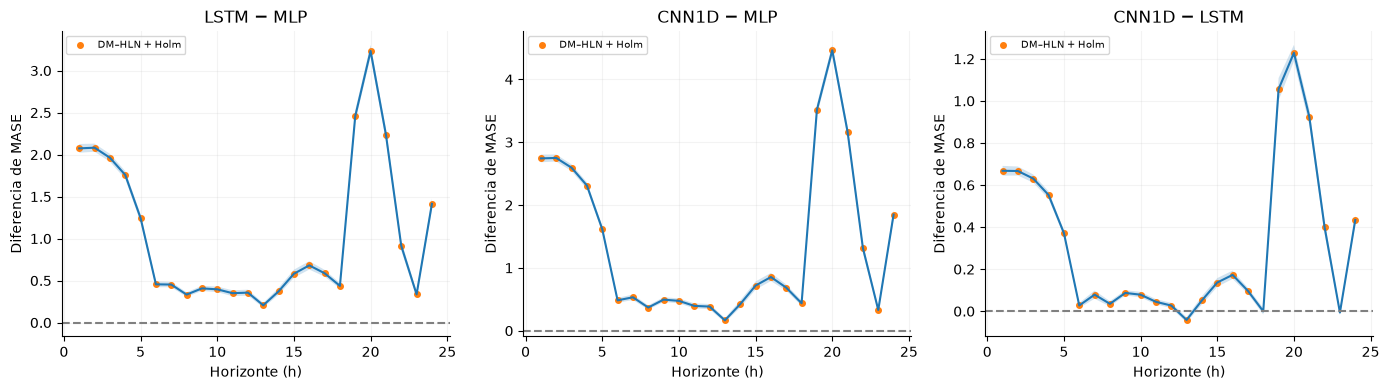

In [6]:
dm_h=[]
for familia,pares in familias.items():
    for a,b in pares:
        for h in range(24):
            d=loss_h[b][:,h]-loss_h[a][:,h]
            estadistico,p=dm_hln(d,14)
            rep=boot_h[b][:,h]-boot_h[a][:,h]
            ci=np.quantile(rep,[.025,.975])
            dm_h.append({'Familia':familia,'A':a,'B':b,'horizonte':h+1,
                'Delta_MASE_B_menos_A':float(d.mean()),'IC95_inf':ci[0],'IC95_sup':ci[1],
                'DM_HLN':estadistico,'p':p})
dm_h=pd.DataFrame(dm_h)
for fam,idx in dm_h.groupby('Familia').groups.items():
    dm_h.loc[idx,'p_Holm']=multipletests(dm_h.loc[idx,'p'],method='holm')[1]
dm_h.to_csv(OUT/'DM_24_horizontes.csv',index=False)
principal=dm_h.loc[dm_h.Familia=='Neuronales']
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,((a,b),d) in zip(axes,principal.groupby(['A','B'],sort=False)):
    d=d.sort_values('horizonte')
    ax.plot(d.horizonte,d.Delta_MASE_B_menos_A)
    ax.fill_between(d.horizonte.to_numpy(),d.IC95_inf.to_numpy(),d.IC95_sup.to_numpy(),alpha=.2)
    sig=d.p_Holm<.05
    ax.scatter(d.loc[sig,'horizonte'],d.loc[sig,'Delta_MASE_B_menos_A'],s=16,label='DM–HLN + Holm')
    ax.axhline(0,color='grey',ls='--');ax.set(title=etiquetas[b]+' − '+etiquetas[a],xlabel='Horizonte (h)',ylabel='Diferencia de MASE')
    ax.legend(fontsize=7)
fig.tight_layout();display(fig);plt.close(fig)
n_sig_h=int((principal.p_Holm<.05).sum())


70 de las 72 comparaciones horarias neuronales resultan significativas con DM–HLN y Holm. Diferencias positivas favorecen al primer modelo del contraste. Las bandas bootstrap son puntuales al 95 %, mientras los puntos marcados usan corrección conjunta de p; no se interpretan las bandas como cobertura simultánea de las 24 horas.

## Robustez del intervalo frente a la longitud del bloque

Se repite el remuestreo con 7 y 28 días como sensibilidad previamente fijada, manteniendo 14 días como análisis principal. Se conserva la estratificación anual y no se elige el bloque que produzca el menor p.

In [7]:
sensibilidad=[]
for longitud in [7,14,28]:
    if longitud==14:
        bdict=boot_d
    else:
        pesos=pesos_bloques(longitud,B,plan['semilla']+longitud)
        bdict={n:pesos@loss_d[n] for n in [*modelos,*refs]}
        del pesos
    for familia,pares in familias.items():
        for a,b in pares:
            m=float((loss_d[b]-loss_d[a]).mean());rep=bdict[b]-bdict[a]
            ci=np.quantile(rep,[.025,.975])
            p=(1+np.sum(np.abs(rep-m)>=abs(m)))/(B+1)
            sensibilidad.append({'bloque_dias':longitud,'Familia':familia,'A':a,'B':b,
                'IC95_inf':ci[0],'IC95_sup':ci[1],'p':p})
sensibilidad=pd.DataFrame(sensibilidad)
for _,idx in sensibilidad.groupby(['bloque_dias','Familia']).groups.items():
    sensibilidad.loc[idx,'p_Holm']=multipletests(sensibilidad.loc[idx,'p'],method='holm')[1]
display(sensibilidad.round(5))
sensibilidad.to_csv(OUT/'sensibilidad_bloques.csv',index=False)
rechazos_bloque=sensibilidad.loc[sensibilidad.Familia=='Neuronales'].groupby('bloque_dias').p_Holm.apply(lambda s:int((s<.05).sum()))
sig7,sig14,sig28=(int(rechazos_bloque[l]) for l in [7,14,28])


,bloque_dias,Familia,A,B,IC95_inf,IC95_sup,p,p_Holm
0,7,Neuronales,mlp,lstm,1.04048,1.07114,0.0001,0.0003
1,7,Neuronales,mlp,cnn1d,1.36056,1.39463,0.0001,0.0003
2,7,Neuronales,lstm,cnn1d,0.31640,0.32718,0.0001,0.0003
3,7,Contexto ARX,mlp,arx_lineal,0.12099,0.15825,0.0001,0.0003
4,7,Contexto ARX,lstm,arx_lineal,-0.93677,-0.89650,0.0001,0.0003
5,7,Contexto ARX,cnn1d,arx_lineal,-1.26039,-1.21647,0.0001,0.0003
6,7,Referencias ingenuas,mlp,ingenuo_24h,1.34515,1.42361,0.0001,0.0003
7,7,Referencias ingenuas,mlp,ingenuo_168h,0.57834,0.75180,0.0001,0.0003
8,7,Referencias ingenuas,mlp,persistencia,3.51189,3.57088,0.0001,0.0003
9,14,Neuronales,mlp,lstm,1.03820,1.07309,0.0001,0.0003


El número de contrastes neuronales significativos es 3, 3 y 3 con bloques de 7, 14 y 28 días, respectivamente. La tabla permite valorar si la conclusión depende de una longitud concreta. Los resultados de sensibilidad no eliminan las limitaciones de presupuesto, revisiones de datos o consulta retrospectiva de prueba.

## Errores por año, calendario y nivel de demanda

Los segmentos se definen antes de calcularlos: año, tipo de día y cuartiles descriptivos de demanda realizada. Los cuartiles usan etiquetas de prueba únicamente para describir errores de modelos ya congelados; no son características ni umbrales de entrenamiento.

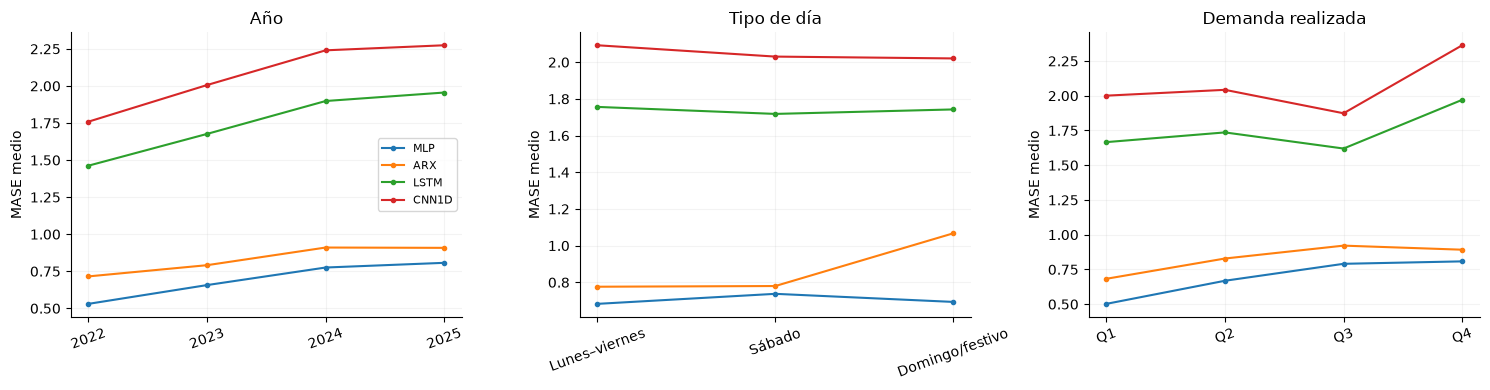

,grupo,segmento,intervalos
0,Año,2022,8760
1,Año,2023,8760
2,Año,2024,8784
3,Año,2025,8760
4,Tipo de día,Lunes–viernes,23520
5,Tipo de día,Sábado,4968
6,Tipo de día,Domingo/festivo,6576
7,Demanda realizada,Q1,8766
8,Demanda realizada,Q2,8766
9,Demanda realizada,Q3,8766


In [8]:
festivos=pd.to_datetime(pd.read_csv(ROOT/'data/external/festivos_colombia.csv').fecha).dt.normalize()
fechas_sin_zona=fechas.tz_localize(None).normalize()
es_festivo=fechas_sin_zona.isin(festivos)
tipo=np.where((fechas.day_of_week==6)|es_festivo,'Domingo/festivo',
              np.where(fechas.day_of_week==5,'Sábado','Lunes–viernes'))
cuartil=pd.qcut(y.ravel(),4,labels=['Q1','Q2','Q3','Q4'])
filas_seg=[]
for nombre in modelos:
    for anio in sorted(set(fechas.year)):
        sel=fechas.year==anio
        filas_seg.append({'modelo':nombre,'grupo':'Año','segmento':str(anio),'intervalos':int(sel.sum()*24),
                          'MASE':float(loss_h[nombre][sel].mean())})
    for t in ['Lunes–viernes','Sábado','Domingo/festivo']:
        sel=tipo==t
        filas_seg.append({'modelo':nombre,'grupo':'Tipo de día','segmento':t,'intervalos':int(sel.sum()*24),
                          'MASE':float(loss_h[nombre][sel].mean())})
    for q in ['Q1','Q2','Q3','Q4']:
        sel=np.asarray(cuartil==q)
        filas_seg.append({'modelo':nombre,'grupo':'Demanda realizada','segmento':q,'intervalos':int(sel.sum()),
                          'MASE':float(loss_h[nombre].ravel()[sel].mean())})
segmentos=pd.DataFrame(filas_seg)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,grupo in zip(axes,['Año','Tipo de día','Demanda realizada']):
    for nombre in modelos:
        d=segmentos[(segmentos.modelo==nombre)&(segmentos.grupo==grupo)]
        ax.plot(d.segmento,d.MASE,marker='o',ms=3,label=etiquetas[nombre])
    ax.set(title=grupo,ylabel='MASE medio');ax.tick_params(axis='x',rotation=20)
axes[0].legend(fontsize=8);fig.tight_layout();display(fig);plt.close(fig)
conteos=segmentos.loc[segmentos.modelo=='mlp',['grupo','segmento','intervalos']]
display(conteos.reset_index(drop=True))
segmentos.to_csv(OUT/'errores_segmentos.csv',index=False)
peor_mlp=segmentos[(segmentos.modelo=='mlp')&(segmentos.grupo=='Año')].sort_values('MASE').iloc[-1]


El mayor error anual de MLP corresponde a 2025, con MASE 0.807. Las diferencias entre tipos de día y cuartiles identifican contextos difíciles que el promedio global comprime. La tabla informa tamaños de segmento, no repite los errores de las gráficas; los cuartiles se interpretan como descripción posterior del desempeño.

## Residuos y errores sistemáticos

Los diagnósticos utilizan la semilla 1000 y el error medio diario firmado de sus 24 horas. Se aplican Ljung–Box a 7, 14 y 28 días, ARCH a 7 y BDS de dimensión 2 sobre los últimos 1.000 días. Holm corrige los veinte contrastes. El rechazo de BDS indica incompatibilidad con i.i.d.; con autocorrelación presente no identifica por sí solo una estructura no lineal.

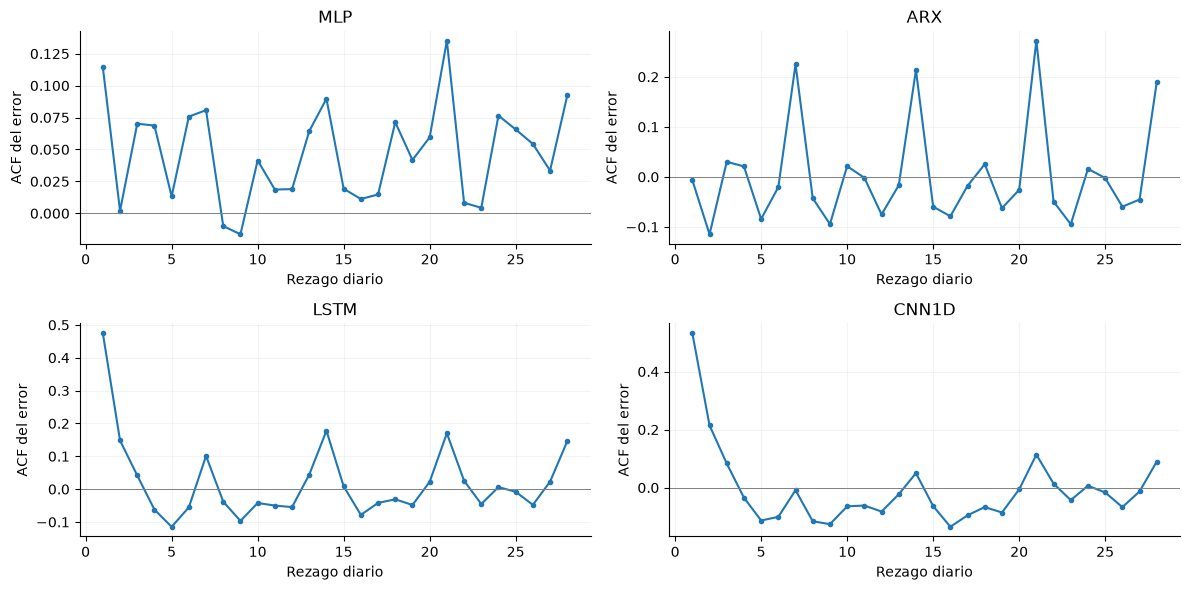

,Modelo,Prueba,Estadistico,p,p_Holm
0,MLP,Ljung–Box 7,51.566,7.11e-09,3.55e-08
1,MLP,Ljung–Box 14,73.670,4.15e-10,2.49e-09
2,MLP,Ljung–Box 28,151.223,7.42e-19,5.93e-18
3,MLP,ARCH 7,10.762,0.149,0.149
4,MLP,BDS dimensión 2,3.116,0.00183,0.00366
5,ARX,Ljung–Box 7,106.796,4.24e-20,3.82e-19
6,ARX,Ljung–Box 14,199.364,7.41e-35,8.15e-34
7,ARX,Ljung–Box 28,411.290,9.86e-70,1.28e-68
8,ARX,ARCH 7,41.634,6.11e-07,1.83e-06
9,ARX,BDS dimensión 2,5.306,1.12e-07,4.49e-07


In [9]:
from statsmodels.stats.diagnostic import acorr_ljungbox,het_arch
from statsmodels.tsa.stattools import acf,bds
diagnosticos=[];fig,axes=plt.subplots(2,2,figsize=(12,6))
for ax,nombre in zip(axes.ravel(),modelos):
    e=resid[nombre];centrado=(e-e.mean())/e.std(ddof=1)
    lb=acorr_ljungbox(centrado,lags=[7,14,28],return_df=True)
    for lag in [7,14,28]:
        diagnosticos.append({'Modelo':etiquetas[nombre],'Prueba':'Ljung–Box '+str(lag),
                            'Estadistico':float(lb.loc[lag,'lb_stat']),'p':float(lb.loc[lag,'lb_pvalue'])})
    lm,p_arch,_,_=het_arch(centrado,nlags=7,result_object=False)
    bs,bp=bds(centrado[-1000:],max_dim=2)
    diagnosticos.extend([
        {'Modelo':etiquetas[nombre],'Prueba':'ARCH 7','Estadistico':float(lm),'p':float(p_arch)},
        {'Modelo':etiquetas[nombre],'Prueba':'BDS dimensión 2','Estadistico':float(bs),'p':float(bp)}])
    ax.plot(np.arange(1,29),acf(centrado,nlags=28,fft=True)[1:],marker='o',ms=3)
    ax.axhline(0,color='grey',lw=.7);ax.set(title=etiquetas[nombre],xlabel='Rezago diario',ylabel='ACF del error')
fig.tight_layout();display(fig);plt.close(fig)
diagnosticos=pd.DataFrame(diagnosticos)
diagnosticos['p_Holm']=multipletests(diagnosticos.p,method='holm')[1]
display(diagnosticos.style.format({'Estadistico':'{:.3f}','p':lambda p:'<1e-300' if p==0 else f'{p:.3g}',
                                  'p_Holm':lambda p:'<1e-300' if p==0 else f'{p:.3g}'}))
diagnosticos.to_csv(OUT/'diagnosticos_residuos.csv',index=False)
n_diag=int((diagnosticos.p_Holm<.05).sum())


19 de los veinte diagnósticos rechazan sus hipótesis tras Holm. La ACF muestra dónde persiste memoria en el error diario; ARCH examina agrupación de magnitudes y BDS independencia. La presencia de estructura remanente orienta mejoras posteriores, sin modificar los modelos ni sus hiperparámetros a partir de esta prueba.

## Síntesis del alcance temporal

La disponibilidad de predicciones y curvas completa los errores de las 24 horas, R², segmentos, trayectorias observadas/predichas, curvas por época, contrastes temporales y residuos. Los intervalos por días complementan la variación entre semillas y no la reemplazan.

Permanecen las limitaciones de diseño: LSTM recibió menor presupuesto de búsqueda, los datos y la prueba son retrospectivos, y el análisis estadístico es secundario. La latencia de inferencia no se registró en la ejecución; disponer de pesos no permite deducirla del tiempo de ajuste. No se ejecutan nuevos modelos ni predicciones para completar ese valor.